# Titanic Survival Prediction

**Objective**  
Now we aim to predict the probability of survival of a passenger based on key features such as gender, age, and passenger class. 
For this purpose, a Logistic Regression model will be trained using these variables as predictors, enabling us to estimate the 
probability that a passenger survived.


In [1]:
import warnings
warnings.filterwarnings('ignore')

Experiment No. 02: Based on training and testing dataset of assignment 1 to predict the
probability of a survival of a person based on gender, age and passenger-class


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Explanation

1. `import pandas as pd` — Imports modules or specific objects. (import pandas as pd)
2. `import numpy as np` — Imports modules or specific objects. (import numpy as np)
3. `import matplotlib.pyplot as plt` — Imports modules or specific objects. (import matplotlib.pyplot as plt)



In [3]:
import os
from google.colab import files # Import the files module from google.colab

uploaded = files.upload() # Use files.upload() to upload a file from your local system

Saving test.csv to test.csv
Saving train.csv to train.csv


### Explanation

**Summary:** This cell imports and uses external libraries.

**Line-by-line explanation:**

1. `import os` — Imports modules or specific objects. (import os)
2. `from google.colab import files # Import the files module from google.colab` — Imports modules or specific objects. (from google.colab import files # Import the files module from google.colab)

3. `uploaded = files.upload() # Use files.upload() to upload a file from your local system` — Assigns a value or object to the variable `uploaded`.



In [5]:
import io # Import the io module to work with in-memory byte streams

training_set = pd.read_csv(io.BytesIO(uploaded['train.csv'])) # Read the uploaded CSV file into a pandas DataFrame
test_set = pd.read_csv(io.BytesIO(uploaded['test.csv'])) # Read the uploaded CSV file into a pandas DataFrame
training_set.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### Explanation

**Summary:** This cell imports and uses external libraries. It loads data from an external file into a DataFrame.



1. `import io # Import the io module to work with in-memory byte streams` — Imports modules or specific objects. (import io # Import the io module to work with in-memory byte streams)
2. `` —
3. `training_set = pd.read_csv(io.BytesIO(uploaded['train.csv'])) # Read the uploaded CSV file into a pandas DataFrame` — Loads data into a pandas DataFrame from file or other source.
4. `test_set = pd.read_csv(io.BytesIO(uploaded['test.csv'])) # Read the uploaded CSV file into a pandas DataFrame` — Loads data into a pandas DataFrame from file or other source.
5. `` —
6. `training_set.head()` —



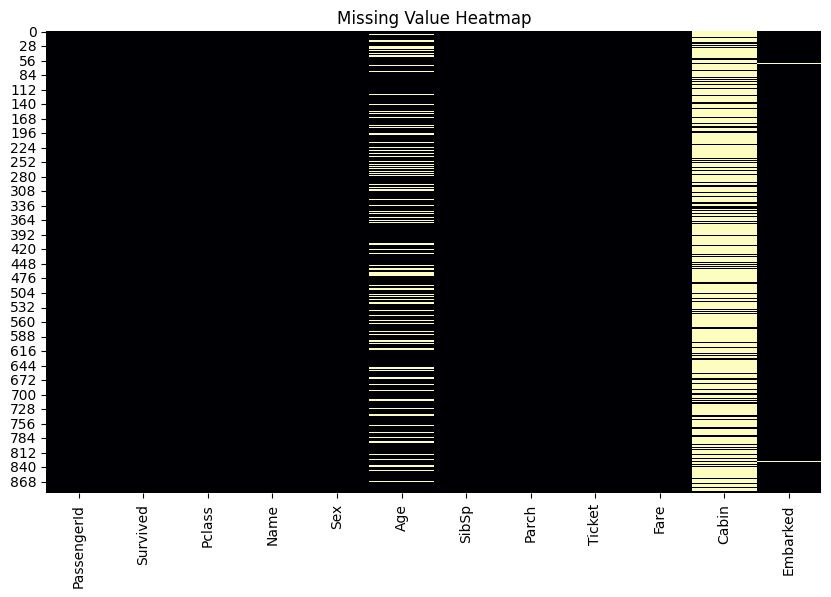

In [6]:
import seaborn as sns
plt.figure(figsize=(10,6))
sns.heatmap(training_set.isnull(), cbar=False, cmap='magma')
plt.title("Missing Value Heatmap")
plt.show()

We could delete the training samples that have NaN values but in this case we dont have a huge
dataset. First we are going to transform the Cabin feature into a Deck feature, each cabin starts
with a letter that denotes the deck and we dont really need more information than that.


In [7]:
# make a list of all the posible Decks, the last element is used when no cabin code is present
cabin_list = ['A', 'B', 'C', 'D', 'E', 'F', 'T', 'G', 'Unknown']

### Explanation

**Summary:** This cell performs data processing or computations.




`cabin_list = ['A', 'B', 'C', 'D', 'E', 'F', 'T', 'G', 'Unknown']` — Assigns a value or object to the variable `cabin_list`.



In [8]:
#define a function that replaces the cabin code with the deck character
def search_substring(big_string, substring_list):
  for substring in substring_list:
    if substring in big_string:
      return substring
  return substring_list[-1]

### Explanation
| Step | Description                                                   | Result                   |
| ---- | ------------------------------------------------------------- | ------------------------ |
| 1    | Iterates through a list of possible substrings (deck letters) | Finds matching letter    |
| 2    | Returns the first matching substring                          | e.g., `'C'` from `'C85'` |
| 3    | If no match found, returns default `'Unknown'`                | handles missing cabins   |

**Summary:** It defines reusable functions.




`def search_substring(big_string, substring_list):` — Defines a function. It encapsulates reusable logic.

`for substring in substring_list:` — Starts a loop to repeat operations.

`if substring in big_string:` — A conditional branch controlling flow based on a condition.

`return substring` — Returns a value from a function.

`return substring_list[-1]` — Returns a value from a function.


We have a similar problem with the Name feature, we have too much information that is hard
to encode and nt useful. So we can take only the title of the name for each person, lets define a
function for that.


In [9]:
# replace passenger's name with his/her title (Mr, Mrs, Miss, Master)
def get_title(string):
  import re
  regex=re.compile(r'Mr|Don|Major|Capt|Jonkheer|Rev|Col|Dr|Mrs|Countess|Dona|Mme|Ms|Miss|Mlle|Master', re.IGNORECASE)
  results = regex.search(string)
  if results != None:
    return(results.group().lower())
  else:
    return(str(np.nan))

### Explanation

**Summary:**

Titles give clues about age and gender.

This can be used to fill missing Age values or group people logically.

It also helps in categorical encoding for model training (like Title → numeric)
| Name                                                | Title |
| --------------------------------------------------- | ----- |
| Braund, Mr. Owen Harris                             | mr    |
| Cumings, Mrs. John Bradley (Florence Briggs Thayer) | mrs   |
| Heikkinen, Miss. Laina                              | miss  |
| Allen, Mr. William Henry                            | mr    |
| Moran, Mr. James                                    | mr    |


In [10]:
# dictionary to map to generate the new feature vector
title_dictionary = {
"capt":"Officer",
"col":"Officer",
"major":"Officer",
"dr":"Officer",
"jonkheer":"Royalty",
"rev":"Officer",
"countess":"Royalty",
"dona":"Royalty",
"lady":"Royalty",
"don":"Royalty",
"mr":"Mr",
"mme":"Mrs",
"ms":"Mrs",
"mrs":"Mrs",
"miss":"Miss",
"mlle":"Miss",
"master":"Master",
"nan":"Mr"
}

Now that we have the functions we need, lets apply them and create the features Title and Deck

In [11]:
training_set['Deck'] = training_set['Cabin'].map(lambda x: search_substring(str(x), cabin_list))
test_set['Deck'] = test_set['Cabin'].map(lambda x: search_substring(str(x), cabin_list))
# delete the Cabin feature
training_set.drop('Cabin', axis=1, inplace=True)
test_set.drop('Cabin', axis=1, inplace=True)
training_set['Title'] = training_set['Name'].apply(get_title)
test_set['Title'] = test_set['Name'].apply(get_title)
training_set['Title'] = training_set['Title'].map(title_dictionary)
test_set['Title'] = test_set['Title'].map(title_dictionary)

In [12]:
# delete the Name feature
training_set.drop('Name', axis=1, inplace=True)
test_set.drop('Name', axis=1, inplace=True)
#Let's take a look at the results we got
training_set.tail()

,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Deck,Title
886,887,0,2,male,27.0,0,0,211536,13.00,S,Unknown,Officer
887,888,1,1,female,19.0,0,0,112053,30.00,S,B,Miss
888,889,0,3,female,NaN,1,2,W./C. 6607,23.45,S,Unknown,Miss
889,890,1,1,male,26.0,0,0,111369,30.00,C,C,Mr
890,891,0,3,male,32.0,0,0,370376,7.75,Q,Unknown,Mr


### Explanation
**Summary:** This cell performs data processing or computations.

**Line-by-line explanation:**

1. `# delete the Name feature`
2. `training_set.drop('Name', axis=1, inplace=True)` — Assigns a value or object to the variable `training_set.drop('Name', axis`.
3. `test_set.drop('Name', axis=1, inplace=True)` — Assigns a value or object to the variable `test_set.drop('Name', axis`.
4. `#Let's take a look at the results we got`
5. `training_set.tail()` —

In [13]:
#dropping ticket column
training_set.drop('Ticket', axis=1, inplace=True)
test_set.drop('Ticket', axis=1, inplace=True)

### Explanation

**Summary:** This cell performs data processing or computations.



1. `#dropping ticket column` — Inline comment.
2. `training_set.drop('Ticket', axis=1, inplace=True)` — Assigns a value or object to the variable `training_set.drop('Ticket', axis`.
3. `test_set.drop('Ticket', axis=1, inplace=True)` — Assigns a value or object to the variable `test_set.drop('Ticket', axis`.



We have to do something about the NaN values in the Age column. We can replace them with
the mean of the age, but that would mean that some kid (Master or Miss) would appear to be
older than they are. So we will take the mean of the age from each Title, and then replace each
NaN value with the mean of the age of the corresponding persons title.


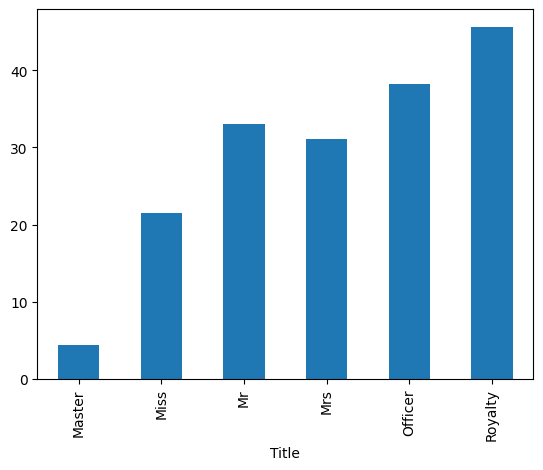

In [14]:
means_title = training_set.groupby('Title')['Age'].mean()
mk = training_set.groupby('Title')['Age'].mean().plot(kind='bar')

### Explanation

**Summary:** It defines reusable functions.



1. `means_title = training_set.groupby('Title')['Age'].mean()` — Assigns a value or object to the variable `means_title`.
2. `title_list = ['Mr','Miss','Mrs','Master', 'Royalty', 'Officer']` — Assigns a value or object to the variable `title_list`.
3. `def age_nan_replace(means, dframe, title_list):` — Defines a function. It encapsulates reusable logic.
4. `for title in title_list:` — Starts a loop to repeat operations.
5. `temp = dframe['Title'] == title #extract indices of samples with same title` — Assigns a value or object to the variable `temp`.
6. `dframe.loc[temp, 'Age'] = dframe.loc[temp, 'Age'].fillna(means[title]) # replace nan values for mean` — Assigns a value or object to the variable `dframe.loc[temp, 'Age']`.
7. `age_nan_replace(means_title, training_set, title_list)` — (
8. `age_nan_replace(means_title, test_set, title_list)` —

In [15]:
title_list = ['Mr','Miss','Mrs','Master', 'Royalty', 'Officer']
def age_nan_replace(means, dframe, title_list):
  for title in title_list:
    temp = dframe['Title'] == title #extract indices of samples with same title
    dframe.loc[temp, 'Age'] = dframe.loc[temp, 'Age'].fillna(means[title]) # replace nan values for mean
age_nan_replace(means_title, training_set, title_list)
age_nan_replace(means_title, test_set, title_list)

Now lets fill those two NaN cases in the Embarked column.


### Explanation

**Summary:** This cell performs data processing or computations.


 `training_set.groupby('Embarked').size().plot(kind='bar')` — Assigns a value or object to the variable `training_set.groupby('Embarked').size().plot(kind`.

<Axes: xlabel='Embarked'>

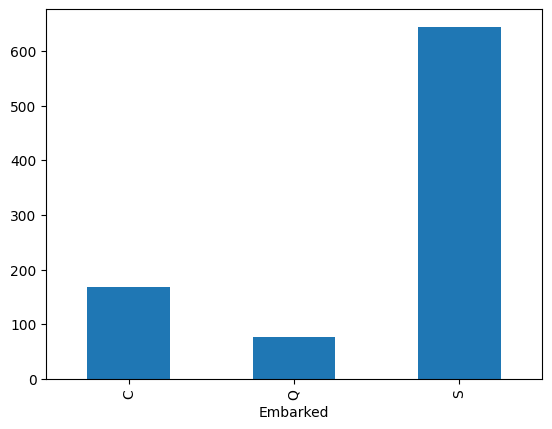

In [16]:
training_set.groupby('Embarked').size().plot(kind='bar')

### Explanation

**The Embarked column indicates the port of embarkation:**

C = Cherbourg

Q = Queenstown

S = Southampton

Some rows have missing embarkation data (NaN).

Using .fillna('S', inplace=True) replaces these NaN values with 'S'.

Why 'S'? Because most passengers boarded at Southampton — it’s the most frequent port, so using it preserves data distribution.

**The Fare column represents the ticket price.**

The test set often has a few missing values in Fare.

Replacing them with the mean fare (test_set['Fare'].mean()) ensures there are no nulls that could cause model errors.

This approach (imputation) is simple and effective when missingness is rare.



In [17]:
training_set['Embarked'].fillna('S', inplace=True)
test_set['Embarked'].fillna('S', inplace=True)
#fill the fare column in the test set
test_set['Fare'].fillna(test_set['Fare'].mean(), inplace=True)
training_set.head()

,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Deck,Title
0,1,0,3,male,22.0,1,0,7.2500,S,Unknown,Mr
1,2,1,1,female,38.0,1,0,71.2833,C,C,Mr
2,3,1,3,female,26.0,0,0,7.9250,S,Unknown,Miss
3,4,1,1,female,35.0,1,0,53.1000,S,C,Mr
4,5,0,3,male,35.0,0,0,8.0500,S,Unknown,Mr


Let's visualize some aspects of the data so that we can understand what are the most important
factors that determined survival.


| Survived | female                               | male                               |
| -------- | ------------------------------------ | ---------------------------------- |
| 0        | number of females who didn’t survive | number of males who didn’t survive |
| 1        | number of females who survived       | number of males who survived       |


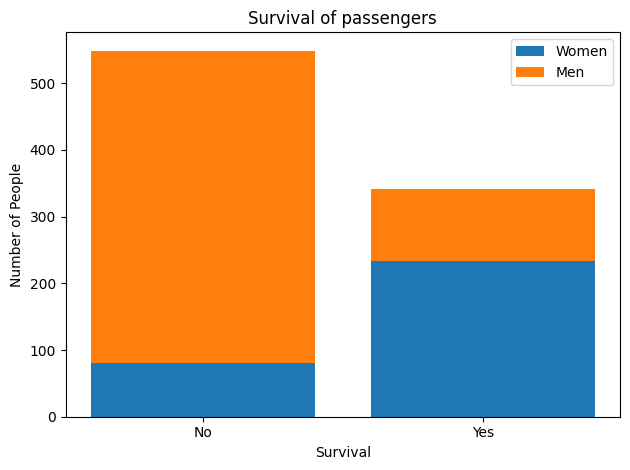

In [18]:
index = training_set['Survived'].unique() # get the number of bars
grouped_data = training_set.groupby(['Survived', 'Sex'])
temp = grouped_data.size().unstack()
women_stats = (temp.iat[0,0], temp.iat[1,0])
men_stats = (temp.iat[0,1], temp.iat[1,1])
p1 = plt.bar(index, women_stats)
p2 = plt.bar(index, men_stats, bottom=women_stats)
plt.xticks(index, ('No', 'Yes'))
plt.ylabel('Number of People')
plt.xlabel('Survival')
plt.title('Survival of passengers')
plt.legend((p1[0], p2[0]), ('Women', 'Men'))
plt.tight_layout()

**Plot** two bars for each survival status (No = 0, Yes = 1).

bottom=women_stats stacks men’s bars on top of women’s bars.

Legend distinguishes genders.

**Insight**:

The bar for “Yes” will show more women than men — reflecting the “women and children first” rule during the disaster.

The “No” bar will show many more men than women.

<Axes: xlabel='Sex'>

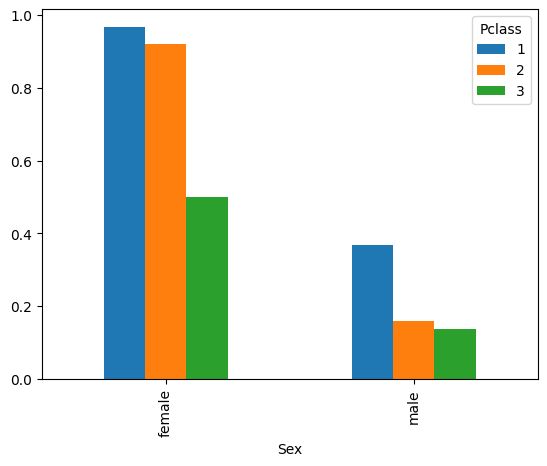

In [19]:
training_set.pivot_table('Survived',index='Sex',columns='Pclass').plot(kind='bar')

**Pivot table with:**

index='Sex' → rows are male/female

columns='Pclass' → columns are passenger classes (1, 2, 3)

Values = mean survival rate (since 'Survived' is 0/1)

Then plots it as a bar chart.

**Insight**:

Women in 1st and 2nd class have the highest survival rate.

Men in 3rd class have the lowest

<Axes: xlabel='Title'>

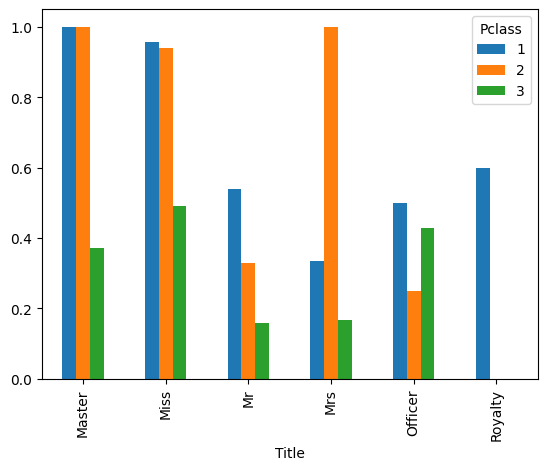

In [20]:
training_set.pivot_table('Survived', index='Title', columns='Pclass').plot(kind='bar')

Mrs” and “Miss” often have higher survival rates; “Mr” lower.

<Axes: xlabel='Sex,Age'>

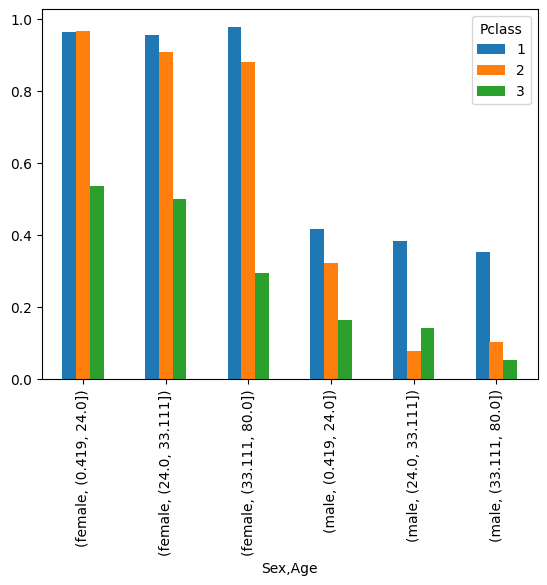

In [21]:
age_intervals = pd.qcut(training_set['Age'], 3)
training_set.pivot_table('Survived', ['Sex', age_intervals], 'Pclass').plot(kind='bar')

pd.qcut(..., 3) divides ages into three equal-sized quantile ranges.

Then a pivot table is created across:

Index: Sex and age range

Columns: Pclass

Values: survival rate

**Insight**:

Younger passengers (especially females) in higher classes show higher survival probability.

Older passengers or lower classes show reduced rates.

<Axes: xlabel='Parch'>

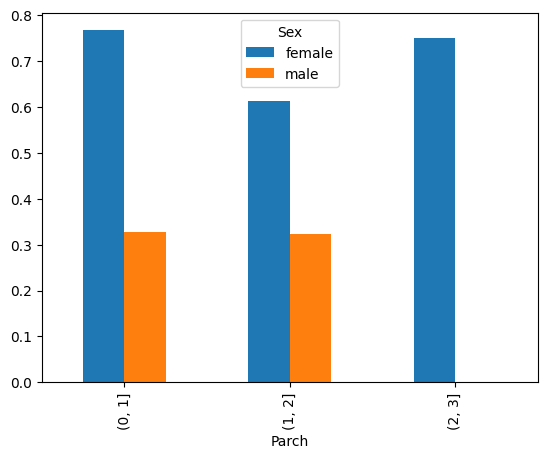

In [22]:
parch_intervals = pd.cut(training_set['Parch'], [0,1,2,3]) #Parents/Children (Parch)
training_set.pivot_table('Survived', parch_intervals, 'Sex').plot(kind='bar')

<Axes: xlabel='SibSp'>

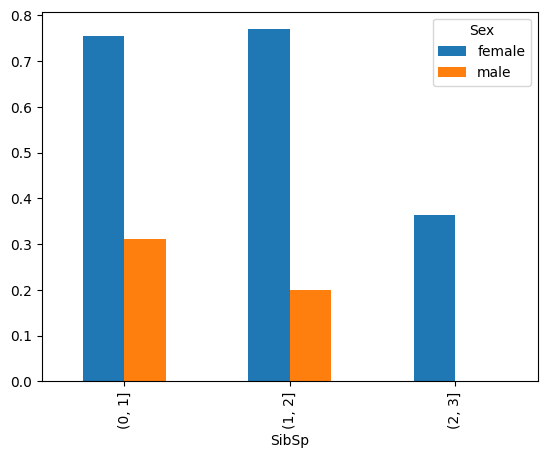

In [23]:
sibsp_intervals = pd.cut(training_set['SibSp'], [0,1,2,3]) #Siblings/Spouses (SibSp)
training_set.pivot_table('Survived', sibsp_intervals, 'Sex').plot(kind='bar')

What we can take from this analysis is that Passenger Class was relevant to survive, and that
the features SibSp and Parch behave similarly. We can make a new feature called Family Size
that is the sum of those 2 feature columns.


In [24]:
training_set['Family Size'] = training_set['Parch'] + training_set['SibSp']
test_set['Family Size'] = test_set['Parch'] + test_set['SibSp']
training_set.drop('Parch', axis=1, inplace=True)
training_set.drop('SibSp', axis=1, inplace=True)
test_set.drop('Parch', axis=1, inplace=True)
test_set.drop('SibSp', axis=1, inplace=True)
training_set.head()

,PassengerId,Survived,Pclass,Sex,Age,Fare,Embarked,Deck,Title,Family Size
0,1,0,3,male,22.0,7.2500,S,Unknown,Mr,1
1,2,1,1,female,38.0,71.2833,C,C,Mr,1
2,3,1,3,female,26.0,7.9250,S,Unknown,Miss,0
3,4,1,1,female,35.0,53.1000,S,C,Mr,1
4,5,0,3,male,35.0,8.0500,S,Unknown,Mr,0


### Explanation

**Summary:** This cell performs data processing or computations.



1. `training_set['Family Size'] = training_set['Parch'] + training_set['SibSp']` — Assigns a value or object to the variable `training_set['Family Size']`.
2. `test_set['Family Size'] = test_set['Parch'] + test_set['SibSp']` — Assigns a value or object to the variable `test_set['Family Size']`.
3. `training_set.drop('Parch', axis=1, inplace=True)` — Assigns a value or object to the variable `training_set.drop('Parch', axis`.
4. `training_set.drop('SibSp', axis=1, inplace=True)` — Assigns a value or object to the variable `training_set.drop('SibSp', axis`.
5. `test_set.drop('Parch', axis=1, inplace=True)` — Assigns a value or object to the variable `test_set.drop('Parch', axis`.
6. `test_set.drop('SibSp', axis=1, inplace=True)` — Assigns a value or object to the variable `test_set.drop('SibSp', axis`.
7. `training_set.head()` — ()


Let's standardize the numerical features Age and Fare

In [25]:
from sklearn.preprocessing import StandardScaler
numericals_list = ['Age','Fare']
for column in numericals_list:
  sc = StandardScaler(with_mean=True, with_std=True)
  # print(training_set[column].size)
  # print(test_set[column].size)
  sc.fit(training_set[column].values.reshape(-1,1))
  training_set[column] = sc.transform(training_set[column].values.reshape(-1,1))
  test_set[column] = sc.transform(test_set[column].values.reshape(-1,1))

### Explanation

**Summary:**



This code performs feature scaling — a preprocessing step that ensures all numerical features have comparable scales.
It specifically applies standardization (Z-score normalization) to the Age and Fare columns in both the training and test datasets.

Machine learning algorithms (like Logistic Regression, SVM, and Neural Networks) work better when numeric data has similar ranges.
Without scaling, a large-valued feature (like Fare, which might be 512) can dominate smaller-valued features (like Age, around 30).


Now let's encode categorical classes with sklearn's LabelEncoder


In [26]:
from sklearn.preprocessing import LabelEncoder
categorical_classes_list = ['Sex','Embarked','Deck', 'Title'] #Pclass is already encoded
#encode features that are cateorical classes
encoding_list = []
for column in categorical_classes_list:
  le = LabelEncoder()
  le.fit(training_set[column])
  encoding_list.append(training_set[column].unique())
  encoding_list.append(list(le.transform(training_set[column].unique())))
  training_set[column] = le.transform(training_set[column])
  test_set[column] = le.transform(test_set[column])

### Explanation

**Summary:**


This code converts categorical features (`Sex`, `Embarked`, `Deck`, and `Title`) into numerical values using **Label Encoding** so that machine learning algorithms, which require numeric input, can process them effectively.

For each column, a **LabelEncoder** assigns a unique integer to every category (e.g., `male → 1`, `female → 0`). The encoder is first **fitted on the training set** to learn these mappings, and then the **same mappings are applied to the test set** to ensure consistency between both datasets during model training and evaluation.


In [27]:
# lets see the results
training_set.head()

,PassengerId,Survived,Pclass,Sex,Age,Fare,Embarked,Deck,Title,Family Size
0,1,0,3,1,-0.587428,-0.502445,2,8,2,1
1,2,1,1,0,0.617618,0.786845,0,2,2,1
2,3,1,3,0,-0.286167,-0.488854,2,8,1,0
3,4,1,1,0,0.391672,0.420730,2,2,2,1
4,5,0,3,1,0.391672,-0.486337,2,8,2,0


Now we are going to onehot encode categorical features such as Embarked, Title and Pclass

### Explanation

**Summary:** This cell performs data processing or computations.



1. `training_set = pd.get_dummies(training_set, columns=['Embarked','Pclass','Title', 'Deck'])` — Uses pandas for data manipulation or DataFrame operations.
2. `test_set = pd.get_dummies(test_set, columns=['Embarked','Pclass','Title', 'Deck'])` — Uses pandas for data manipulation or DataFrame operations.



In [28]:
training_set = pd.get_dummies(training_set, columns=['Embarked','Pclass','Title', 'Deck'])
test_set = pd.get_dummies(test_set, columns=['Embarked','Pclass','Title', 'Deck'])

The test set lacks a sample where deck 7 is selected so we will have to align the dataframes to
fill that column.



### Explanation

**Summary:** This cell performs data processing or computations.


1. `training_set, test_set = training_set.align(test_set, axis=1)` — Assigns a value or object to the variable `training_set, test_set`.
2. `test_set.drop('Survived', axis=1, inplace=True)` — Assigns a value or object to the variable `test_set.drop('Survived', axis`.
3. `test_set.fillna(0, axis=1, inplace=True)` — Assigns a value or object to the variable `test_set.fillna(0, axis`.


In [29]:

training_set, test_set = training_set.align(test_set, axis=1)
test_set.drop('Survived', axis=1, inplace=True)
test_set.fillna(0, axis=1, inplace=True)

Now that we have our dataset clean and ready, we need to transform it into a numpy matrix
that a learning algorithm can use. We will get a Y vector containing the labels for training, a
matrix X that has all the features for training, and X_test that has all the samples for training
from the test set.

### Explanation

**Summary:** This cell performs data processing or computations.



1. `#test_set.fillna(0, inplace=True)` — Inline comment.
2. `y = training_set['Survived'].values` — Assigns a value or object to the variable `y`.
3. `X = training_set.drop(['Survived','PassengerId'], axis=1).values` — Assigns a value or object to the variable `X`.
4. `X_test = test_set.drop('PassengerId', axis=1).values` — Assigns a value or object to the variable `X_test`.



In [30]:
#test_set.fillna(0, inplace=True)
y = training_set['Survived'].values
X = training_set.drop(['Survived','PassengerId'], axis=1).values
X_test = test_set.drop('PassengerId', axis=1).values

Correlations with 'Survived':
Survived       1.000000
Title_1        0.318480
Pclass_1       0.285904
Fare           0.257307
Deck_1         0.175095
Embarked_0     0.168240
Deck_3         0.150716
Deck_4         0.150716
Deck_2         0.114652
Pclass_2       0.093349
Title_0        0.079305
Deck_5         0.047930
Deck_0         0.022287
Title_5        0.019667
Family Size    0.016639
Deck_6         0.016040
Title_3        0.007887
Embarked_1     0.003650
Title_4       -0.002337
PassengerId   -0.005007
Deck_7        -0.026456
Age           -0.094568
Embarked_2    -0.149683
Title_2       -0.316449
Deck_8        -0.316912
Pclass_3      -0.322308
Sex           -0.543351
Name: Survived, dtype: float64


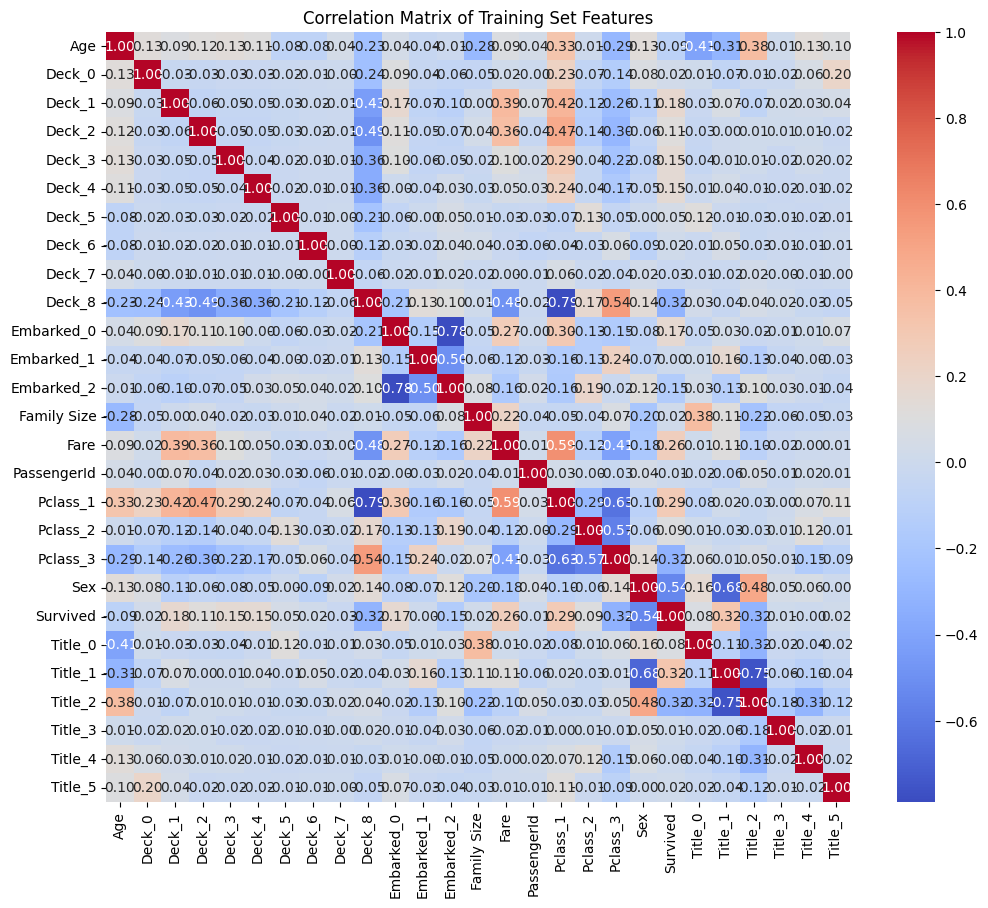

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate the correlation matrix
corr_matrix = training_set.corr()

# Get correlations with 'Survived'
survived_corr = corr_matrix['Survived'].sort_values(ascending=False)

# Display the correlations
print("Correlations with 'Survived':")
print(survived_corr)

# Plot the correlation matrix
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm')
plt.title('Correlation Matrix of Training Set Features')
plt.show()

In [32]:
# Show the proportion of survivors in the training set
survived_counts = training_set['Survived'].value_counts(normalize=True)
print("Proportion of Survived in Training Set:")
print(survived_counts)

Proportion of Survived in Training Set:
Survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64


In [33]:
print(training_set.columns)

Index(['Age', 'Deck_0', 'Deck_1', 'Deck_2', 'Deck_3', 'Deck_4', 'Deck_5',
       'Deck_6', 'Deck_7', 'Deck_8', 'Embarked_0', 'Embarked_1', 'Embarked_2',
       'Family Size', 'Fare', 'PassengerId', 'Pclass_1', 'Pclass_2',
       'Pclass_3', 'Sex', 'Survived', 'Title_0', 'Title_1', 'Title_2',
       'Title_3', 'Title_4', 'Title_5'],
      dtype='object')


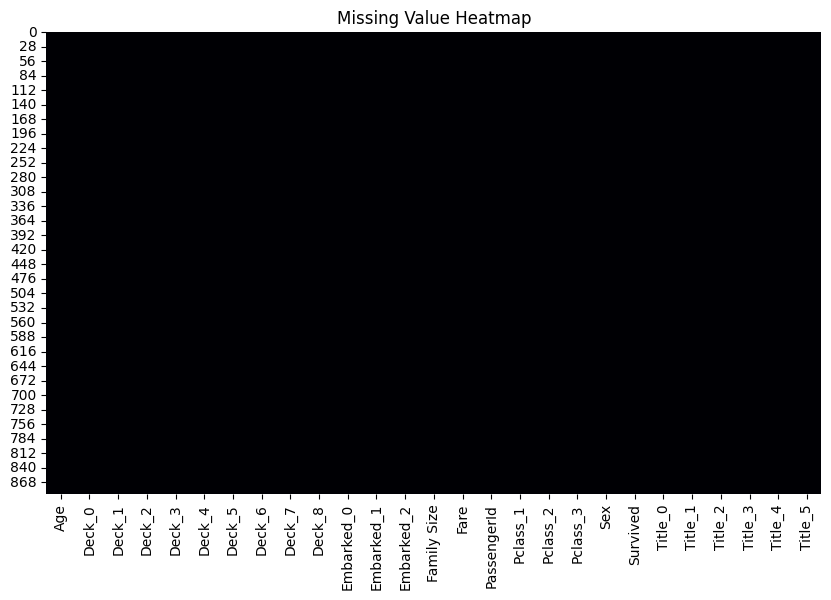

In [34]:
plt.figure(figsize=(10,6))
sns.heatmap(training_set.isnull(), cbar=False, cmap='magma')
plt.title("Missing Value Heatmap")
plt.show()
